File Check

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/raw/paysim.csv")

print("File exists:", DATA_PATH.exists())
print("File size (MB):", round(DATA_PATH.stat().st_size / 1024**2, 1))

File exists: True
File size (MB): 470.7


In [3]:
peek = pd.read_csv(DATA_PATH, nrows=5)
peek

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
dtypes = {
    "step": "uint16",
    "type": "category",
    "amount": "float64",
    "oldbalanceOrg": "float64",
    "newbalanceOrig": "float64",
    "oldbalanceDest": "float64",
    "newbalanceDest": "float64",
    "isFraud": "int8",
    "isFlaggedFraud": "int8",
}

df = pd.read_csv(DATA_PATH, usecols=list(dtypes), dtype=dtypes)

In [5]:
print("Shape (rows, columns):", df.shape)
df.info(memory_usage="deep")

Shape (rows, columns): (6362620, 9)
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 9 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            uint16  
 1   type            category
 2   amount          float64 
 3   oldbalanceOrg   float64 
 4   newbalanceOrig  float64 
 5   oldbalanceDest  float64 
 6   newbalanceDest  float64 
 7   isFraud         int8    
 8   isFlaggedFraud  int8    
dtypes: category(1), float64(5), int8(2), uint16(1)
memory usage: 273.1 MB


In [6]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,0


In [7]:
df.tail()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,339682.13,0.0,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,6311409.28,0.0,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,6311409.28,0.0,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,850002.52,0.0,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,850002.52,0.0,6510099.11,7360101.63,1,0


In [8]:
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 20

balance_cols = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

In [9]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print("\nTotal missing values:", missing.sum())

dup_count = df.duplicated().sum()
print("\nExact duplicate rows:", dup_count)

Missing values per column:
step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Total missing values: 0

Exact duplicate rows: 543


In [10]:
print("Rows with amount <= 0:", (df["amount"] <= 0).sum())
print("Rows with any negative balance:", (df[balance_cols] < 0).any(axis=1).sum())
print("step range:", df["step"].min(), "to", df["step"].max())
print("Distinct step values:", df["step"].nunique())

Rows with amount <= 0: 16
Rows with any negative balance: 0
step range: 1 to 743
Distinct step values: 743


In [11]:
df[["step", "amount"] + balance_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.00",243.40,142.33,1.00,156.00,239.00,335.00,743.00
amount,"6,362,620.00","179,861.90","603,858.23",0.00,"13,389.57","74,871.94","208,721.48","92,445,516.64"
oldbalanceOrg,"6,362,620.00","833,883.10","2,888,242.67",0.00,0.00,"14,208.00","107,315.18","59,585,040.37"
newbalanceOrig,"6,362,620.00","855,113.67","2,924,048.50",0.00,0.00,0.00,"144,258.41","49,585,040.37"
oldbalanceDest,"6,362,620.00","1,100,701.67","3,399,180.11",0.00,0.00,"132,705.66","943,036.71","356,015,889.35"
newbalanceDest,"6,362,620.00","1,224,996.40","3,674,128.94",0.00,0.00,"214,661.44","1,111,909.25","356,179,278.92"


In [12]:
counts = df["isFraud"].value_counts().sort_index()
percent = (counts / len(df) * 100).round(4)

summary = pd.DataFrame({"count": counts, "percent": percent})
summary.index = ["Genuine (0)", "Fraud (1)"]
print(summary)

ratio = counts.loc[0] / counts.loc[1]
print(f"\nImbalance ratio: about {ratio:,.0f} genuine transactions per 1 fraud")

               count  percent
Genuine (0)  6354407    99.87
Fraud (1)       8213     0.13

Imbalance ratio: about 774 genuine transactions per 1 fraud


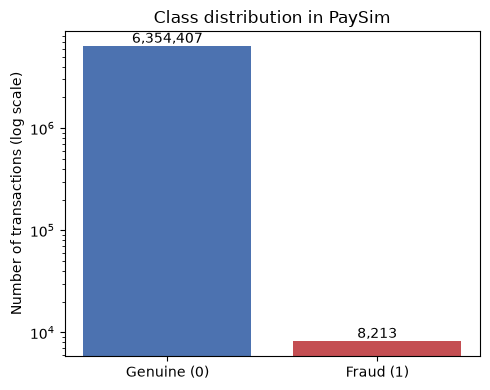

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Genuine (0)", "Fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution in PaySim")

for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("../reports/figures/01_class_distribution.png", dpi=150)
plt.show()

In [14]:
type_summary = pd.DataFrame({
    "count": df["type"].value_counts(),
    "percent": (df["type"].value_counts(normalize=True) * 100).round(2)
})
type_summary

,count,percent
type,,
CASH_OUT,2237500,35.17
PAYMENT,2151495,33.81
CASH_IN,1399284,21.99
TRANSFER,532909,8.38
DEBIT,41432,0.65


Skewness of amount: 30.99


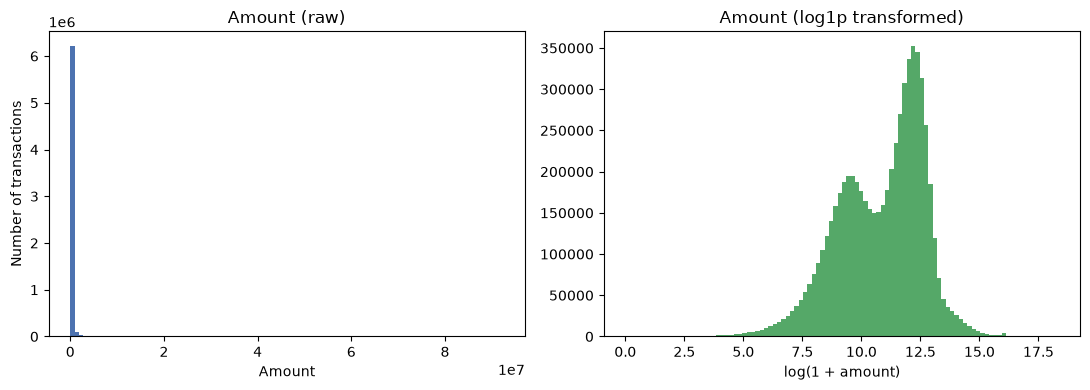

In [15]:
print("Skewness of amount:", round(df["amount"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["amount"], bins=100, color="#4C72B0")
axes[0].set_title("Amount (raw)")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Number of transactions")

axes[1].hist(np.log1p(df["amount"]), bins=100, color="#55A868")
axes[1].set_title("Amount (log1p transformed)")
axes[1].set_xlabel("log(1 + amount)")

plt.tight_layout()
plt.savefig("../reports/figures/02_amount_distribution.png", dpi=150)
plt.show()

In [16]:
extras = df.duplicated()
print("Extra copies (what removal would delete):", extras.sum())
print("  of which fraud:", df.loc[extras, "isFraud"].sum())

group_mask = df.duplicated(keep=False)
dups = df[group_mask]
print("\nAll rows that belong to a duplicate group:", len(dups))

print("\nBy fraud label:")
print(dups["isFraud"].value_counts())

print("\nBy transaction type:")
print(dups["type"].value_counts())

print("\nDuplicate rows with amount = 0:", (dups["amount"] == 0).sum())

dups.sort_values(["step", "type", "amount"]).head(10)

Extra copies (what removal would delete): 543
  of which fraud: 16

All rows that belong to a duplicate group: 1081

By fraud label:
isFraud
0    1054
1      27
Name: count, dtype: int64

By transaction type:
type
PAYMENT     1054
CASH_OUT      27
CASH_IN        0
DEBIT          0
TRANSFER       0
Name: count, dtype: int64

Duplicate rows with amount = 0: 2


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
10884,7,PAYMENT,"1,849.50",0.00,0.00,0.00,0.00,0,0
11104,7,PAYMENT,"1,849.50",0.00,0.00,0.00,0.00,0,0
27043,8,PAYMENT,"7,759.31",0.00,0.00,0.00,0.00,0,0
33556,8,PAYMENT,"7,759.31",0.00,0.00,0.00,0.00,0,0
51253,9,PAYMENT,"2,388.93",0.00,0.00,0.00,0.00,0,0
59969,9,PAYMENT,"2,388.93",0.00,0.00,0.00,0.00,0,0
48847,9,PAYMENT,"2,783.83",0.00,0.00,0.00,0.00,0,0
63096,9,PAYMENT,"2,783.83",0.00,0.00,0.00,0.00,0,0
56420,9,PAYMENT,"6,499.28",0.00,0.00,0.00,0.00,0,0
72575,9,PAYMENT,"6,499.28",0.00,0.00,0.00,0.00,0,0


In [17]:
zero_amt = df[df["amount"] == 0]
print("Zero-amount rows:", len(zero_amt))
print("\nBy fraud label:")
print(zero_amt["isFraud"].value_counts())
print("\nBy type (zero counts are just empty categories):")
print(zero_amt["type"].value_counts())
zero_amt

Zero-amount rows: 16

By fraud label:
isFraud
1    16
Name: count, dtype: int64

By type (zero counts are just empty categories):
type
CASH_OUT    16
CASH_IN      0
DEBIT        0
PAYMENT      0
TRANSFER     0
Name: count, dtype: int64


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
3247298,250,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
3760289,279,CASH_OUT,0.00,0.00,0.00,"538,547.63","538,547.63",1,0
5563714,387,CASH_OUT,0.00,0.00,0.00,"7,970,766.57","7,970,766.57",1,0
5996408,425,CASH_OUT,0.00,0.00,0.00,"76,759.90","76,759.90",1,0
5996410,425,CASH_OUT,0.00,0.00,0.00,"2,921,531.34","2,921,531.34",1,0
6168500,554,CASH_OUT,0.00,0.00,0.00,"230,289.66","230,289.66",1,0
6205440,586,CASH_OUT,0.00,0.00,0.00,"1,328,472.86","1,328,472.86",1,0
6266414,617,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
6281483,646,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0


## Decisions so far (Phase 2, Part B)
- No missing values, so no imputation is needed.
- No negative amounts or balances.
- 543 exact duplicate rows (16 are fraud): KEPT. nameOrig/nameDest were not loaded, so they cannot be proven to be errors, and removal would shrink the fraud class.
- 16 zero-amount rows (all CASH_OUT, all fraud): KEPT. Simulator quirk, to be noted in limitations.
- No outlier clipping: very large amounts may be exactly where fraud lives.
- Fraud rate 0.13% (8,213 of 6,362,620), about 774 genuine per fraud.
- amount is heavily skewed, so a log transform is planned for Phase 3.

In [18]:
ct = pd.crosstab(df["type"], df["isFraud"])
ct.columns = ["genuine", "fraud"]
ct["total"] = ct["genuine"] + ct["fraud"]
ct["fraud_rate_%"] = (ct["fraud"] / ct["total"] * 100).round(4)
ct["share_of_all_fraud_%"] = (ct["fraud"] / ct["fraud"].sum() * 100).round(2)
ct.sort_values("fraud", ascending=False)

,genuine,fraud,total,fraud_rate_%,share_of_all_fraud_%
type,,,,,
CASH_OUT,2233384,4116,2237500,0.18,50.12
TRANSFER,528812,4097,532909,0.77,49.88
CASH_IN,1399284,0,1399284,0.00,0.00
DEBIT,41432,0,41432,0.00,0.00
PAYMENT,2151495,0,2151495,0.00,0.00


In [19]:
print(df.groupby("isFraud")["amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T)

risky = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
print("\nWithin TRANSFER and CASH_OUT only:")
print(risky.groupby(["type", "isFraud"], observed=True)["amount"].agg(["count", "median", "mean", "max"]))

isFraud             0             1
count    6,354,407.00      8,213.00
mean       178,197.04  1,467,967.30
std        596,236.98  2,404,252.95
min              0.01          0.00
25%         13,368.40    127,091.33
50%         74,684.72    441,423.44
75%        208,364.76  1,517,771.48
95%        515,610.42  8,006,429.04
max     92,445,516.64 10,000,000.00

Within TRANSFER and CASH_OUT only:
                    count     median         mean           max
type     isFraud                                               
CASH_OUT 0        2233384 146,946.56   173,917.16  2,847,566.62
         1           4116 435,516.91 1,455,102.59 10,000,000.00
TRANSFER 0         528812 486,521.91   906,229.01 92,445,516.64
         1           4097 445,705.76 1,480,891.67 10,000,000.00


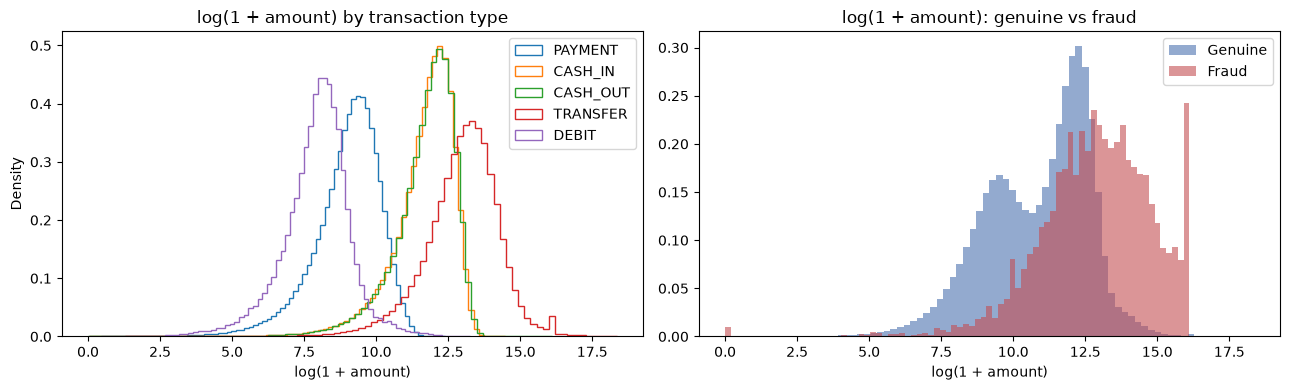

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for t in ["PAYMENT", "CASH_IN", "CASH_OUT", "TRANSFER", "DEBIT"]:
    vals = np.log1p(df.loc[df["type"] == t, "amount"])
    axes[0].hist(vals, bins=80, histtype="step", density=True, label=t)
axes[0].set_title("log(1 + amount) by transaction type")
axes[0].set_xlabel("log(1 + amount)")
axes[0].set_ylabel("Density")
axes[0].legend()

genuine_amt = np.log1p(df.loc[df["isFraud"] == 0, "amount"])
fraud_amt = np.log1p(df.loc[df["isFraud"] == 1, "amount"])
axes[1].hist(genuine_amt, bins=80, density=True, alpha=0.6, label="Genuine", color="#4C72B0")
axes[1].hist(fraud_amt, bins=80, density=True, alpha=0.6, label="Fraud", color="#C44E52")
axes[1].set_title("log(1 + amount): genuine vs fraud")
axes[1].set_xlabel("log(1 + amount)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../reports/figures/03_amount_by_type_and_class.png", dpi=150)
plt.show()

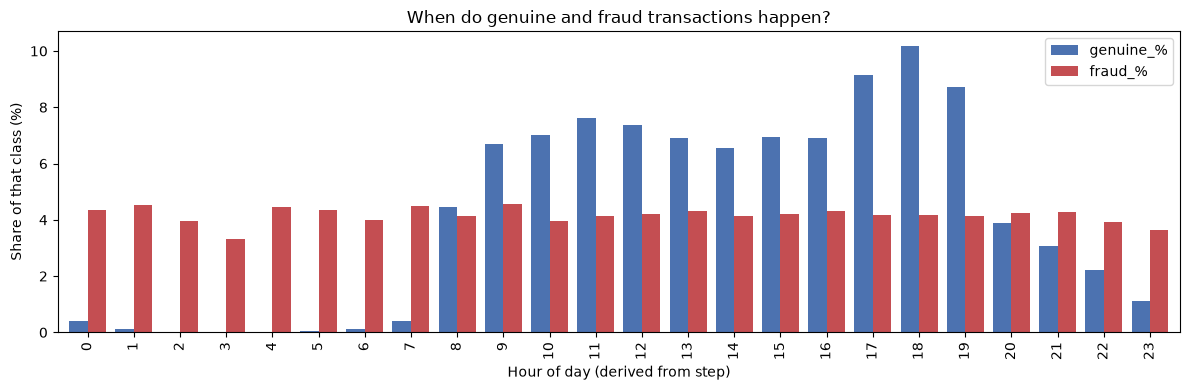

Steps with the most fraud:
step
212    40
523    30
249    28
387    28
425    28
Name: count, dtype: int64

Fraud per day (day 1 = steps 1-24):
count    31.00
mean    264.94
std      23.46
min     216.00
25%     251.00
50%     262.00
75%     275.00
max     320.00
dtype: float64


In [21]:
hour = ((df["step"] - 1) % 24).rename("hour")

by_hour = pd.crosstab(hour, df["isFraud"], normalize="columns") * 100
by_hour.columns = ["genuine_%", "fraud_%"]

ax = by_hour.plot(kind="bar", figsize=(12, 4), color=["#4C72B0", "#C44E52"], width=0.8)
ax.set_xlabel("Hour of day (derived from step)")
ax.set_ylabel("Share of that class (%)")
ax.set_title("When do genuine and fraud transactions happen?")
plt.tight_layout()
plt.savefig("../reports/figures/04_hour_of_day.png", dpi=150)
plt.show()

fraud_by_step = df.loc[df["isFraud"] == 1, "step"].value_counts()
print("Steps with the most fraud:")
print(fraud_by_step.head(5))
print("\nFraud per day (day 1 = steps 1-24):")
print(df.loc[df["isFraud"] == 1].groupby((df["step"] - 1) // 24 + 1).size().describe())

In [22]:
print(pd.crosstab(df["isFraud"], df["isFlaggedFraud"]))

flagged = df[df["isFlaggedFraud"] == 1]
caught = int(((df["isFraud"] == 1) & (df["isFlaggedFraud"] == 1)).sum())
total_fraud = int((df["isFraud"] == 1).sum())

print("\nRows flagged by the rule:", len(flagged))
print("Types among flagged rows:")
print(flagged["type"].value_counts())
print("Smallest flagged amount:", flagged["amount"].min())
print(f"\nFraud caught by the rule: {caught} of {total_fraud} ({caught / total_fraud * 100:.2f}%)")

big_transfers = df[(df["type"] == "TRANSFER") & (df["amount"] > 200000)]
print("\nTRANSFERs above 200,000:", len(big_transfers))
print("  of which fraud:", int(big_transfers["isFraud"].sum()))
print("  of which flagged by the rule:", int(big_transfers["isFlaggedFraud"].sum()))

isFlaggedFraud        0   1
isFraud                    
0               6354407   0
1                  8197  16

Rows flagged by the rule: 16
Types among flagged rows:
type
TRANSFER    16
CASH_IN      0
CASH_OUT     0
DEBIT        0
PAYMENT      0
Name: count, dtype: int64
Smallest flagged amount: 353874.22

Fraud caught by the rule: 16 of 8213 (0.19%)

TRANSFERs above 200,000: 409110
  of which fraud: 2740
  of which flagged by the rule: 16


## Decisions (Phase 2, Part C1)
- Fraud exists only in TRANSFER (4,097) and CASH_OUT (4,116). CASH_IN, PAYMENT, DEBIT have zero fraud (simulator design).
- Model scope: TRANSFER + CASH_OUT only (2,770,409 rows, 0.30% fraud). Other types are routed to a "not covered" message, never labelled safe.
- Limitation: real fraud (e.g. scam payments) can occur in other types; PaySim cannot represent it.
- hour_of_day = (step - 1) % 24 is a planned feature (fraud is flat across hours; genuine traffic is near zero at night).
- isFlaggedFraud dropped (16 flagged rows, 0.19% recall). Used only as a baseline.
- Fraud amounts are capped at 10,000,000 (simulator artifact).

In [23]:
df_s = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
df_s["type"] = df_s["type"].cat.remove_unused_categories()

print("Shape:", df_s.shape)
print(df_s["isFraud"].value_counts())
print(f"Fraud rate: {df_s['isFraud'].mean() * 100:.3f}%")

Shape: (2770409, 9)
isFraud
0    2762196
1       8213
Name: count, dtype: int64
Fraud rate: 0.296%


In [24]:
tol = 0.01
amt = df_s["amount"]

df_s["orig_ok"] = np.isclose(df_s["oldbalanceOrg"] - amt, df_s["newbalanceOrig"], rtol=0, atol=tol)
df_s["dest_ok"] = np.isclose(df_s["oldbalanceDest"] + amt, df_s["newbalanceDest"], rtol=0, atol=tol)
df_s["orig_emptied"] = df_s["newbalanceOrig"] == 0
df_s["dest_untouched"] = df_s["oldbalanceDest"] == df_s["newbalanceDest"]

checks = ["orig_ok", "dest_ok", "orig_emptied", "dest_untouched"]
summary = (df_s.groupby(["type", "isFraud"], observed=True)[checks].mean() * 100).round(1)
summary

orig_ok  dest_ok  orig_emptied  dest_untouched
type     isFraud                                                
CASH_OUT 0          10.80    77.30         88.70            0.10
         1          99.40    86.80        100.00            0.40
TRANSFER 0           3.80    77.90         96.00            0.00
         1          99.50     0.00         96.10           99.30

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

df_s["hour"] = ((df_s["step"] - 1) % 24).astype("int8")
df_s["is_transfer"] = (df_s["type"] == "TRANSFER").astype("int8")
df_s["orig_err"] = (df_s["oldbalanceOrg"] - df_s["amount"] - df_s["newbalanceOrig"]).astype("float32")
df_s["dest_err"] = (df_s["oldbalanceDest"] + df_s["amount"] - df_s["newbalanceDest"]).astype("float32")

feature_sets = {
    "A: amount, hour, type (no balances)": ["amount", "hour", "is_transfer"],
    "B1: old balances only": ["oldbalanceOrg", "oldbalanceDest"],
    "B2: new balances only": ["newbalanceOrig", "newbalanceDest"],
    "C: derived balance errors": ["orig_err", "dest_err"],
}

idx_train, idx_test = train_test_split(
    df_s.index, test_size=0.3, stratify=df_s["isFraud"], random_state=42
)
y_train = df_s.loc[idx_train, "isFraud"]
y_test = df_s.loc[idx_test, "isFraud"]

rows = []
for name, cols in feature_sets.items():
    tree = DecisionTreeClassifier(max_depth=6, random_state=42)
    tree.fit(df_s.loc[idx_train, cols], y_train)
    proba = tree.predict_proba(df_s.loc[idx_test, cols])[:, 1]
    rows.append({
        "features": name,
        "PR-AUC": round(average_precision_score(y_test, proba), 3),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
    })

pd.DataFrame(rows)

,features,PR-AUC,ROC-AUC
0,"A: amount, hour, type (no balances)",0.33,0.84
1,B1: old balances only,0.34,0.93
2,B2: new balances only,0.16,0.80
3,C: derived balance errors,0.35,0.97


In [26]:
prefix_parts = []
fraud_name_parts = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["nameOrig", "nameDest", "isFraud"],
    chunksize=500_000,
):
    prefix_parts.append(pd.DataFrame({
        "orig_prefix": chunk["nameOrig"].str[0],
        "dest_prefix": chunk["nameDest"].str[0],
    }))
    fraud_name_parts.append(chunk.loc[chunk["isFraud"] == 1, ["nameOrig", "nameDest"]])

prefixes = pd.concat(prefix_parts, ignore_index=True).astype("category")
fraud_names = pd.concat(fraud_name_parts, ignore_index=True)

print("Rows read:", len(prefixes), "| matches df:", len(prefixes) == len(df))

print("\nDestination prefix by type, full dataset:")
print(pd.crosstab(df["type"], prefixes["dest_prefix"]))

df_s["orig_prefix"] = prefixes["orig_prefix"].loc[df_s.index].values
df_s["dest_prefix"] = prefixes["dest_prefix"].loc[df_s.index].values

print("\nIn-scope rows, by origin and destination prefix:")
print(pd.crosstab(df_s["orig_prefix"], df_s["dest_prefix"]))

print("\nFraud rows:", len(fraud_names))
print("Unique origin accounts in fraud:", fraud_names["nameOrig"].nunique())
print("Unique destination accounts in fraud:", fraud_names["nameDest"].nunique())
print("\nMost-used destination accounts in fraud:")
print(fraud_names["nameDest"].value_counts().head(5))

Rows read: 6362620 | matches df: True

Destination prefix by type, full dataset:
dest_prefix        C        M
type                         
CASH_IN      1399284        0
CASH_OUT     2237500        0
DEBIT          41432        0
PAYMENT            0  2151495
TRANSFER      532909        0

In-scope rows, by origin and destination prefix:
dest_prefix        C
orig_prefix         
C            2770409

Fraud rows: 8213
Unique origin accounts in fraud: 8213
Unique destination accounts in fraud: 8169

Most-used destination accounts in fraud:
nameDest
C410033330     2
C803116137     2
C904300960     2
C1013511446    2
C2020337583    2
Name: count, dtype: int64


In [27]:
b = df_s[["type", "isFraud", "amount", "oldbalanceOrg"]].copy()
b["old_zero"] = b["oldbalanceOrg"] == 0
b["drains"] = (b["oldbalanceOrg"] > 0) & np.isclose(b["amount"], b["oldbalanceOrg"], rtol=0, atol=0.01)
b["amount_exceeds_balance"] = b["amount"] > b["oldbalanceOrg"] + 0.01

(b.groupby(["type", "isFraud"], observed=True)[["old_zero", "drains", "amount_exceeds_balance"]].mean() * 100).round(1)

old_zero  drains  amount_exceeds_balance
type     isFraud                                          
CASH_OUT 0           45.90    0.00                   88.70
         1            0.90   99.00                    0.60
TRANSFER 0           53.50    0.00                   96.00
         1            0.10   96.20                    0.10

## Decisions (Phase 2, Part C2): final feature plan
- Scope: TRANSFER + CASH_OUT only (2,770,409 rows; 8,213 fraud; 0.296%).
- Main feature set A: log1p(amount), hour = (step-1) % 24, is_transfer.
- Dropped: newbalanceOrig/newbalanceDest (post-outcome; fraud TRANSFER receiver unchanged in 99.3% vs 0.0% genuine), derived balance errors, isFlaggedFraud (0.19% recall), nameOrig/nameDest (all 8,213 fraud senders unique), C/M prefix (constant in scope).
- oldbalanceOrg/oldbalanceDest: excluded from the main model; optional Feature Set B experiment in Phase 4, reported separately and labelled as possibly inflated by simulator artefacts.
- step is used only for the time-based split, not as a feature.
- hour ablation planned: genuine traffic is near zero at hours 0-7, fraud is flat (~4%/hr).
- Probe (random split, depth-6 tree, diagnostic only): A PR-AUC 0.33, B1 0.34, B2 0.16, C 0.35; ROC-AUC 0.84 / 0.93 / 0.80 / 0.97. PR-AUC gap was smaller than expected, so the main evidence for leakage is the arithmetic table, not the probe.
- Limitations: fraud only in 2 of 5 types; fraud amounts capped at 10,000,000; 16 zero-amount fraud rows; fraud accounts are single-use, so no account-history or graph features.


## Decisions (Phase 2, C2.5): the old-balance shortcut
- Genuine rows: sender balance recorded as 0 in 46-54%; amount exceeds the sender's balance in 89-96% (impossible in a real ledger, so a simulator property).
- Fraud rows: amount equals the entire sender balance in 96-99% (simulator's fraud scenario: take over and empty the account).
- "amount == oldbalanceOrg" therefore separates classes almost perfectly in this dataset, but only because genuine rows do not follow accounting rules.
- Feature Set B (amount/oldbalanceOrg ratio, empties_account flag) uses pre-transaction data only, so it is not leakage, but results will be reported separately and flagged as inflated by a simulator artefact.
- Feature Set A (log1p(amount), hour, is_transfer) remains the main model.